# Point processes

Companion notebook to [point_processes.md](../../notes/spatial_statistics/point_processes.md).
We simulate CSR, clustered (Thomas), inhomogeneous and inhibited patterns, and compare intensity, the nearest-neighbor
distribution $G(r)$ and Ripley's $K$ with theory and Monte Carlo envelopes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from math import pi
rng = np.random.default_rng(7)
L = 10.0                      # window [0, L]^2
AREA = L * L

def csr(lam, rng=rng):
    n = rng.poisson(lam * AREA)
    return rng.uniform(0, L, (n, 2))

def thomas(kappa, mu, sigma, rng=rng):
    parents = rng.uniform(-3 * sigma, L + 3 * sigma, (rng.poisson(kappa * (L + 6 * sigma) ** 2), 2))
    pts = [p + rng.normal(0, sigma, (rng.poisson(mu), 2)) for p in parents]
    pts = np.vstack(pts) if pts else np.empty((0, 2))
    keep = (pts >= 0).all(1) & (pts <= L).all(1)
    return pts[keep]

def inhomogeneous(b0, b1, rng=rng):
    lam = lambda x: np.exp(b0 + b1 * x)
    lam_max = lam(L)
    cand = csr(lam_max)
    keep = rng.uniform(size=len(cand)) < lam(cand[:, 0]) / lam_max   # thinning
    return cand[keep]

def hardcore(n, h, rng=rng, tries=20000):
    pts = []
    for _ in range(tries):
        c = rng.uniform(0, L, 2)
        if all(np.hypot(*(c - p)) >= h for p in pts):
            pts.append(c)
        if len(pts) == n:
            break
    return np.array(pts)

## 1. Four patterns, same window

CSR has no structure; Thomas has latent parents; the inhomogeneous pattern has a gradient but independent events
(it *looks* clustered); the hard-core pattern forbids pairs closer than $h$.

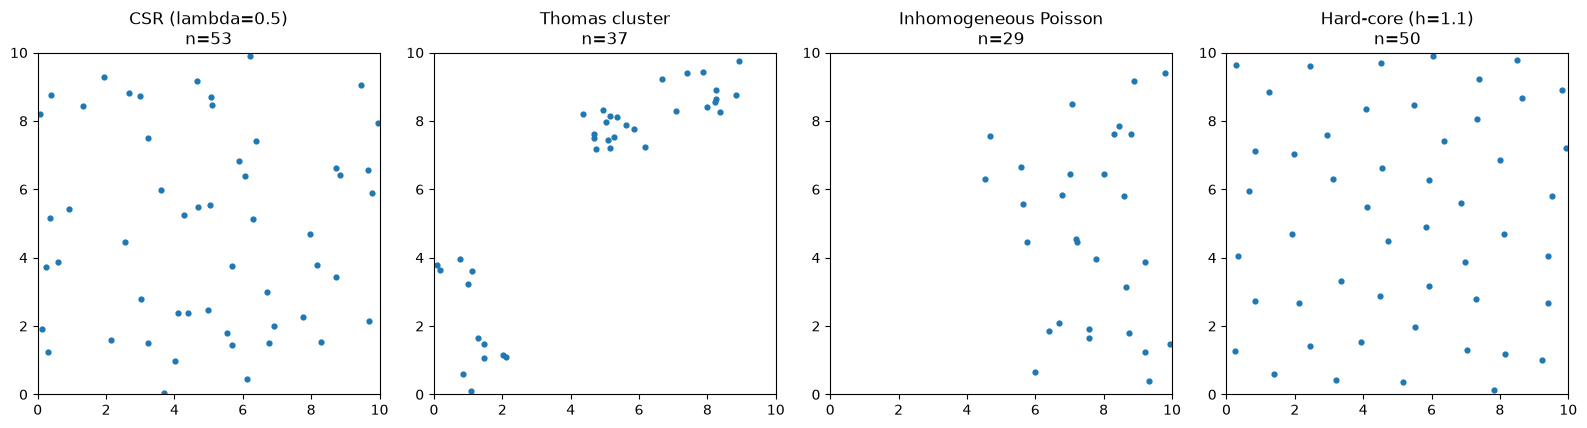

In [2]:
pats = {
    "CSR (lambda=0.5)": csr(0.5),
    "Thomas cluster": thomas(0.05, 10, 0.5),
    "Inhomogeneous Poisson": inhomogeneous(-3.5, 0.35),
    "Hard-core (h=1.1)": hardcore(50, 1.1),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (k, p) in zip(axes, pats.items()):
    ax.scatter(p[:, 0], p[:, 1], s=12); ax.set_title(f"{k}\nn={len(p)}")
    ax.set_xlim(0, L); ax.set_ylim(0, L); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

## 2. Counts and intensity

For CSR with $\lambda=0.5$ and $|B|=12$ we expect $\lambda|B|=6$ events; counts follow Poisson(6).
Estimated intensity is $n/|W|$.

In [3]:
from scipy.stats import poisson
B = (0, 4, 0, 3)  # [0,4]x[0,3], area 12
counts = []
for _ in range(2000):
    p = csr(0.5)
    counts.append(((p[:, 0] <= B[1]) & (p[:, 1] <= B[3])).sum())
counts = np.array(counts)
print("mean count:", counts.mean().round(3), " var:", counts.var().round(3), " (theory 6, 6)")
print("P(N=3) empirical", (counts == 3).mean().round(3), " Poisson", poisson.pmf(3, 6).round(3))
for k, p in pats.items():
    print(f"{k:24s} lambda_hat = {len(p)/AREA:.3f}")

mean count: 6.01  var: 5.899  (theory 6, 6)
P(N=3) empirical 0.1  Poisson 0.089
CSR (lambda=0.5)         lambda_hat = 0.530
Thomas cluster           lambda_hat = 0.370
Inhomogeneous Poisson    lambda_hat = 0.290
Hard-core (h=1.1)        lambda_hat = 0.500


## 3. Nearest-neighbor distribution $G(r)$

Under CSR, $G(r)=1-e^{-\lambda\pi r^2}$. We compute the empirical $G$ with a border (reduced-sample) correction:
only events farther than $r$ from the window edge are used at radius $r$.

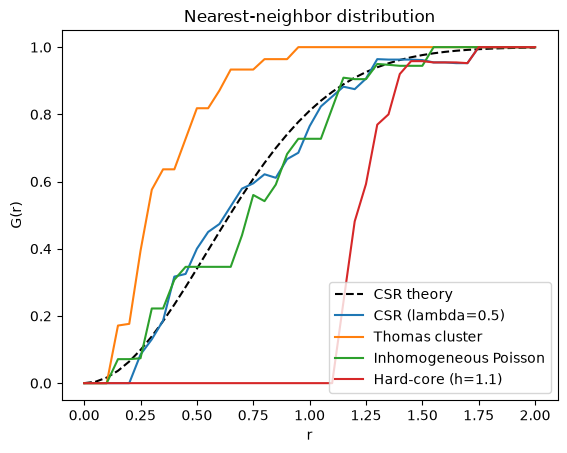

In [4]:
def nn_dist(p):
    D = squareform(pdist(p)); np.fill_diagonal(D, np.inf)
    return D.min(1)

def G_hat(p, rs):
    d = nn_dist(p)
    edge = np.minimum(p, L - p).min(1)
    out = []
    for r in rs:
        use = edge >= r
        out.append((d[use] <= r).mean() if use.any() else np.nan)
    return np.array(out)

rs = np.linspace(0, 2.0, 41)
lam_hat = len(pats["CSR (lambda=0.5)"]) / AREA
plt.plot(rs, 1 - np.exp(-lam_hat * pi * rs**2), "k--", label="CSR theory")
for k, p in pats.items():
    plt.plot(rs, G_hat(p, rs), label=k)
plt.xlabel("r"); plt.ylabel("G(r)"); plt.legend(); plt.title("Nearest-neighbor distribution"); plt.show()

Clustered patterns rise faster than the CSR curve, inhibited patterns stay at zero until $r\approx h$ and then rise steeply.
The inhomogeneous pattern also rises faster than its *homogeneous* CSR benchmark: a first-order effect, not interaction.

In [5]:
print("theory G(2) for lambda=0.08:", round(1 - np.exp(-0.08 * pi * 4), 4), "(note: 0.634)")

theory G(2) for lambda=0.08: 0.6341 (note: 0.634)


## 4. Ripley's $K$ with border correction and Monte Carlo envelope

$\hat K(r)=\dfrac{|W|}{n(n-1)}\sum_{i\neq j}I(d_{ij}\le r)$ using only focal points at least $r$ from the boundary
(border method; denominator uses the number of retained focal points and $\hat\lambda=n/|W|$).
We then simulate 199 CSR patterns with $n$ fixed to the observed count and plot $\hat L(r)-r$ with a pointwise 95% envelope.

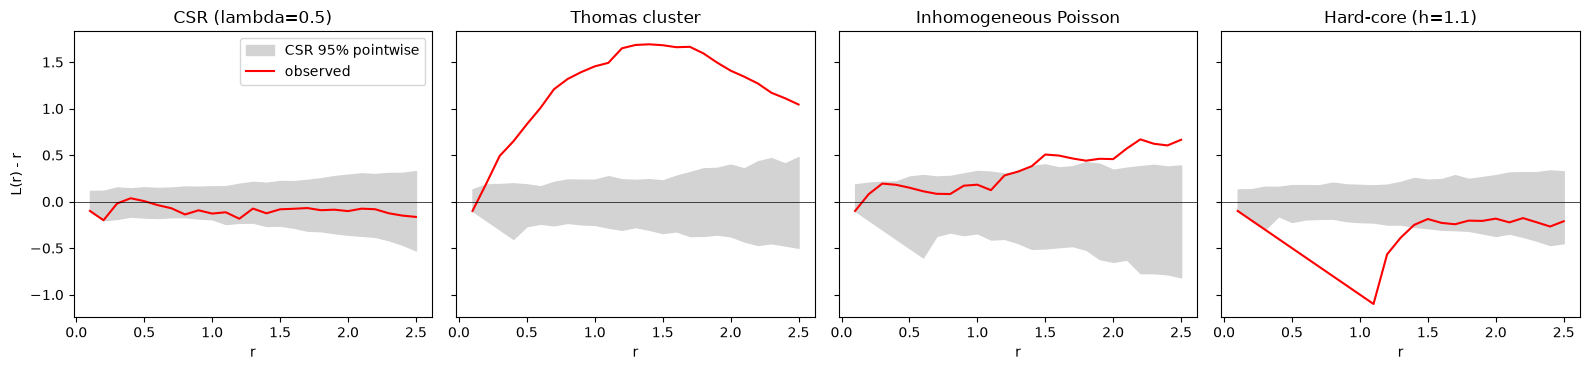

In [6]:
def K_hat(p, rs):
    n = len(p)
    D = squareform(pdist(p))
    edge = np.minimum(p, L - p).min(1)
    lam = n / AREA
    out = []
    for r in rs:
        use = edge >= r
        if use.sum() < 2:
            out.append(np.nan); continue
        cnt = ((D[use] <= r).sum(1) - 1)       # exclude self
        out.append(cnt.mean() / lam)
    return np.array(out)

rs = np.linspace(0.1, 2.5, 25)
def L_minus_r(p):
    return np.sqrt(K_hat(p, rs) / pi) - rs

def envelope(n, nsim=199):
    sims = np.array([L_minus_r(rng.uniform(0, L, (n, 2))) for _ in range(nsim)])
    return np.nanquantile(sims, [0.025, 0.975], axis=0)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (k, p) in zip(axes, pats.items()):
    lo, hi = envelope(len(p))
    ax.fill_between(rs, lo, hi, color="lightgray", label="CSR 95% pointwise")
    ax.plot(rs, L_minus_r(p), "r-", label="observed")
    ax.axhline(0, color="k", lw=.5); ax.set_title(k); ax.set_xlabel("r")
axes[0].set_ylabel("L(r) - r"); axes[0].legend(); plt.tight_layout(); plt.show()

Reading the panels: the CSR sample stays inside the band; Thomas lies above (clustering); hard-core lies below at small $r$ (inhibition).
The inhomogeneous Poisson pattern may also leave the band even though events do not interact. To separate this, compare against a fitted
inhomogeneous reference model, shown next.

fitted log-intensity: -3.57 + 0.366 x   (truth -3.5 + 0.35 x)


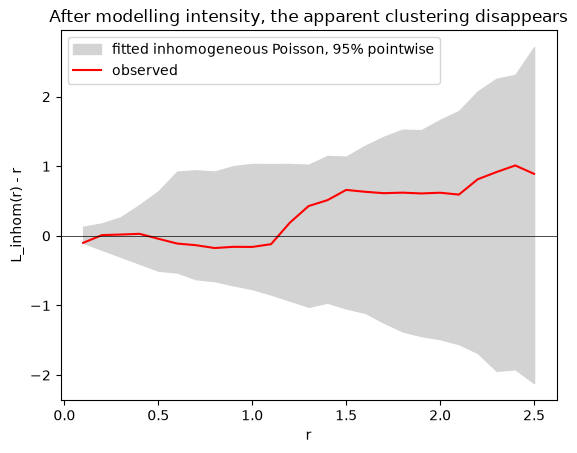

In [7]:
# Reference model: inhomogeneous Poisson, log-intensity linear in x, fitted by Poisson regression on 10 strips
import statsmodels.api as sm
p = pats["Inhomogeneous Poisson"]
edges = np.linspace(0, L, 11)
cnt, _ = np.histogram(p[:, 0], edges)
xc = 0.5 * (edges[1:] + edges[:-1]); strip_area = L * (edges[1] - edges[0])
fit = sm.GLM(cnt, sm.add_constant(xc), family=sm.families.Poisson(),
             offset=np.log(np.full(10, strip_area))).fit()
b0, b1 = fit.params
print("fitted log-intensity: %.2f + %.3f x   (truth -3.5 + 0.35 x)" % (b0, b1))

def Kinhom(p, b0=b0, b1=b1):
    # border-corrected inhomogeneous K: (1/|W_-r|) sum_{i in W_-r} sum_{j != i} 1(d_ij <= r)/(lam_i lam_j)
    lam = np.exp(b0 + b1 * p[:, 0])
    D = squareform(pdist(p)); edge = np.minimum(p, L - p).min(1)
    Wt = 1.0 / np.outer(lam, lam); np.fill_diagonal(Wt, 0)
    out = []
    for r in rs:
        use = edge >= r
        out.append(((D[use] <= r) * Wt[use]).sum() / (L - 2 * r) ** 2)
    return np.array(out)

def Linhom(p):
    return np.sqrt(Kinhom(p) / pi) - rs

sims = np.array([Linhom(inhomogeneous(b0, b1)) for _ in range(199)])
lo, hi = np.quantile(sims, [0.025, 0.975], axis=0)
plt.fill_between(rs, lo, hi, color="lightgray", label="fitted inhomogeneous Poisson, 95% pointwise")
plt.plot(rs, Linhom(p), "r-", label="observed")
plt.axhline(0, color="k", lw=.5); plt.xlabel("r"); plt.ylabel("L_inhom(r) - r"); plt.legend()
plt.title("After modelling intensity, the apparent clustering disappears"); plt.show()

Once the first-order trend is modelled, the observed curve sits inside the band: the visual clustering of this pattern
came from intensity, not interaction. The same check on the Thomas pattern would still show excess clustering.